# 03 — Pesquisa informada: Greedy, A\* e A\* ponderado

Experiências detalhadas da pesquisa informada (`src/informed.py`). A formulação e as heurísticas estão
explicadas no notebook principal, secção 4. Este notebook compara:

* as quatro heurísticas (h1 desvio máximo, h2 arcos mínimos, h3 MST por grupo, h4 relaxação exata por
  grupo) no estado inicial e ao longo de uma solução;
* Greedy vs. A\* vs. A\* ponderado, em custo, nós expandidos e tempo;
* as duas formulações do A\*: uma ação = uma paragem, ou uma ação = uma viagem completa;
* o efeito da regra cronológica no Greedy;
* as rotas encontradas para os 2 veículos do tiny.

In [1]:
import sys, json, time
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import pandas as pd

from src.model import load_problem, evaluate, schedule_table, State, PICKUP, DELIVERY
from src.model import check_solution
from src.model import plot_routes, plot_gantt, plot_histories

pd.set_option("display.max_columns", 30); pd.set_option("display.width", 170)
ROOT = Path.cwd().parent
REPORTS = ROOT / "reports"
RUN_HEAVY = False   # True: volta a correr as pesquisas longas em vez de ler reports/
tiny = load_problem(ROOT / "data" / "tiny")
small = load_problem(ROOT / "data" / "small")
PROBLEMS = {"tiny": tiny, "small": small}

from src.informed import (greedy, astar, astar_trips, weighted_astar, catalog, HEURISTICS, successors,
                          h_mst, h_relaxed)
H = {k: v for k, v in HEURISTICS.items() if k != "h0_zero"}

## 1. Valor das heurísticas

Todas as heurísticas são limites inferiores dos km que faltam. Quanto maior o valor (sem ultrapassar o
custo real), menos nós o A\* precisa de expandir. A tabela compara os valores no estado inicial com o
melhor custo conhecido.

In [2]:
best = json.loads((REPORTS / "best.json").read_text())
rows = []
for ds, p in PROBLEMS.items():
    s0 = State.initial(p)
    for name, h in H.items():
        rows.append(dict(dataset=ds, heuristica=name, h0=round(h(p, s0), 2), melhor_conhecido=best[ds]["km"],
                         razao=round(h(p, s0) / best[ds]["km"], 3)))
pd.DataFrame(rows).pivot(index="heuristica", columns="dataset", values=["h0", "razao"])

h0          razao       
dataset         small    tiny  small   tiny
heuristica                                 
h1_max_detour  104.66   75.32  0.138  0.141
h2_min_arcs    419.05  395.95  0.553  0.743
h3_mst         469.13  441.83  0.619  0.829
h4_relaxed     757.84  533.09  1.000  1.000

Para ver como se comportam ao longo da pesquisa, reconstrói-se a sequência de estados da solução ótima do
tiny (ação a ação). Em cada estado compara-se h com o custo que realmente falta (C\* − g). Uma heurística
admissível fica sempre abaixo da diagonal.

estados no caminho: 25 | custo final: 533.09 | objetivo: True


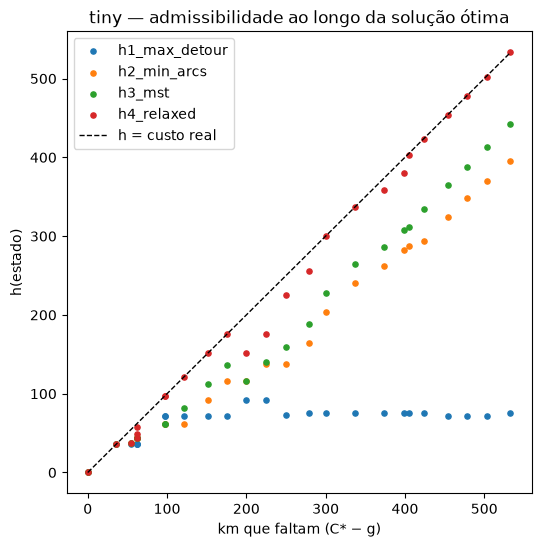

In [3]:
opt = {int(k): v for k, v in json.loads((REPORTS / "solution_tiny_astar.json").read_text()).items()}
opt_small = {int(k): v for k, v in json.loads((REPORTS / "solution_small_astar.json").read_text()).items()}
C_star = evaluate(tiny, opt).km

def replay(p, sol):
    # segue a solução pela ordem cronológica das ações e devolve os estados intermédios
    ev = evaluate(p, sol)
    events = []
    for ts in ev.trips:
        for k, (rid, _, st) in enumerate(ts.stops):
            events.append((st, ts.vid, ("visit", rid)))
        events.append((ts.back, ts.vid, ("close", None)))
    s, out = State.initial(p), []
    for _, vid, (act, rid) in sorted(events):
        out.append(s)
        i = [v.vid for v in s.vehicles].index(vid)
        for c in successors(p, s):
            v = c.vehicles[i]
            if c.vehicles[:i] + c.vehicles[i + 1:] != s.vehicles[:i] + s.vehicles[i + 1:]:
                continue
            if act == "visit" and v.trip and v.trip[-1] == rid and rid in c.served and rid not in s.served:
                s = c; break
            if act == "close" and v.kind is None and s.vehicles[i].kind is not None:
                s = c; break
        else:
            raise RuntimeError(f"ação {act} {rid} não encontrada")
    out.append(s)
    return out

path = replay(tiny, opt)
print("estados no caminho:", len(path), "| custo final:", round(path[-1].g, 2), "| objetivo:", path[-1].is_goal(tiny))
fig, ax = plt.subplots(figsize=(6, 6))
real = [C_star - s.g for s in path]
for name, h in H.items():
    ax.scatter(real, [h(tiny, s) for s in path], s=14, label=name)
ax.plot([0, C_star], [0, C_star], "k--", lw=1, label="h = custo real")
ax.set_xlabel("km que faltam (C* − g)"); ax.set_ylabel("h(estado)"); ax.legend(); ax.set_title("tiny — admissibilidade ao longo da solução ótima");
assert all(h(tiny, s) <= C_star - s.g + 1e-6 for s in path for h in H.values())

## 2. Greedy best-first (executado aqui)

In [4]:
rows = []
for ds, p in PROBLEMS.items():
    for name, h in H.items():
        for chrono in (True, False):
            r = greedy(p, h, chrono=chrono, max_expansions=30_000)
            rows.append(dict(dataset=ds, heuristica=name, regra_cronologica=chrono, **{k: v for k, v in r.summary().items() if k not in ("algorithm", "heuristic")}))
greedy_tab = pd.DataFrame(rows)
greedy_tab

,dataset,heuristica,regra_cronologica,cost_km,expanded,generated,pruned,seconds,found,complete
0,tiny,h1_max_detour,True,707.16,46,156,68,0.005,True,True
1,tiny,h1_max_detour,False,663.81,83,462,195,0.016,True,True
2,tiny,h2_min_arcs,True,674.14,29,91,30,0.004,True,True
3,tiny,h2_min_arcs,False,662.74,27,140,31,0.007,True,True
4,tiny,h3_mst,True,625.46,29,92,36,0.004,True,True
5,tiny,h3_mst,False,625.46,30,130,39,0.007,True,True
6,tiny,h4_relaxed,True,611.13,28,87,30,0.005,True,True
7,tiny,h4_relaxed,False,599.73,43,174,64,0.009,True,True
8,small,h1_max_detour,True,NaN,30000,137727,74745,6.196,False,False
9,small,h1_max_detour,False,NaN,30000,159010,123842,7.692,False,False


A **regra cronológica** expande sempre o veículo com o relógio mais atrasado. Sem ela, o Greedy pode
avançar um veículo para o dia seguinte enquanto o outro ainda tem recolhas por fazer, e depois perde-se
num beco sem saída enorme: no small não encontra solução dentro do orçamento. A regra não é usada no
A\*, porque poderia cortar a solução ótima.

## 3. A\* e A\* ponderado

O A\* exato no tiny demora alguns minutos por heurística. Os números vêm de `reports/informed.csv`,
produzido por `run_experiments.py`.

In [5]:
if RUN_HEAVY:
    for name, h in H.items():
        print(name, astar(tiny, h, max_expansions=1_000_000).summary())
inf = pd.read_csv(REPORTS / "informed.csv")
inf[["dataset", "algorithm", "heuristic_name", "cost_km", "expanded", "generated", "pruned", "seconds", "complete", "item_check"]]

,dataset,algorithm,heuristic_name,cost_km,expanded,generated,pruned,seconds,complete,item_check
0,tiny,Greedy,h1_max_detour,707.16,46,156,68,0.005,True,True
1,tiny,Greedy,h2_min_arcs,674.14,29,91,30,0.004,True,True
2,tiny,Greedy,h3_mst,625.46,29,92,36,0.005,True,True
3,tiny,Greedy,h4_relaxed,611.13,28,87,30,0.005,True,True
4,tiny,A*,h1_max_detour,NaN,1000000,5868823,3881922,202.681,False,NaN
5,tiny,A*,h2_min_arcs,NaN,1000000,5662950,3388804,216.239,False,NaN
6,tiny,A*,h3_mst,533.09,709786,4090385,2359117,179.620,True,True
7,tiny,A*,h4_relaxed,533.09,7302,33048,16194,1.133,True,True
8,tiny,WA*(w=1.2),h3_mst,533.09,100582,568563,319654,19.707,True,True
9,tiny,WA*(w=1.5),h3_mst,533.09,196,1025,381,0.035,True,True


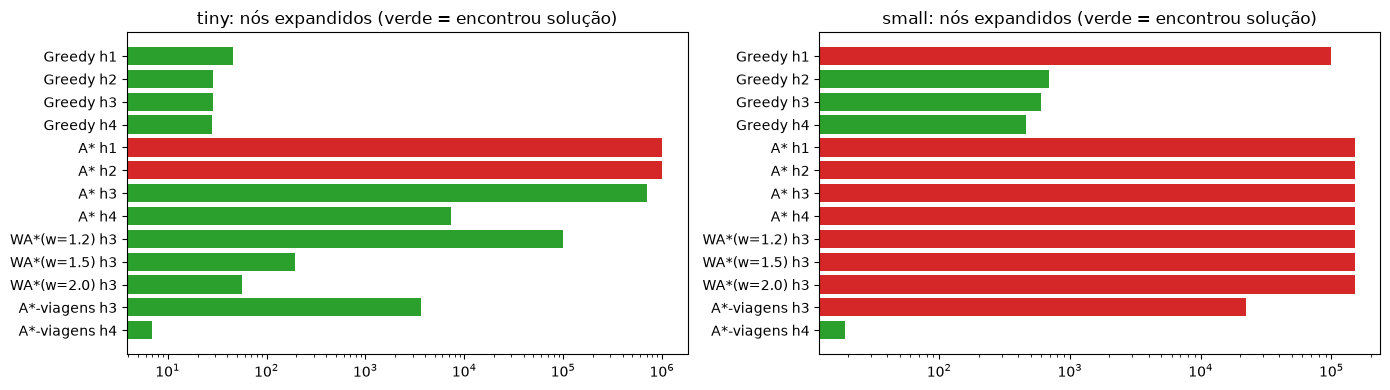

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a_, ds in zip(ax, ("tiny", "small")):
    d = inf[inf.dataset == ds]
    labels = d.algorithm + " " + d.heuristic_name.str.split("_").str[0]
    colors = ["tab:green" if f else "tab:red" for f in d.found]
    a_.barh(labels, d.expanded, color=colors); a_.set_xscale("log"); a_.invert_yaxis()
    a_.set_title(f"{ds}: nós expandidos (verde = encontrou solução)")
fig.tight_layout()

**A\* ponderado** (f = g + w·h): quanto maior w, mais a pesquisa confia na heurística. Expande menos
nós, mas a solução pode ficar até w vezes acima do ótimo. A curva seguinte foi calculada aqui, no tiny,
com h3.

      w      km  expandidos  segundos
0  1.30  533.09        6990     1.145
1  1.40  533.09         411     0.064
2  1.50  533.09         196     0.034
3  1.75  533.09          69     0.018
4  2.00  553.08          56     0.014
5  2.50  553.08          42     0.011
6  3.00  553.08          45     0.012


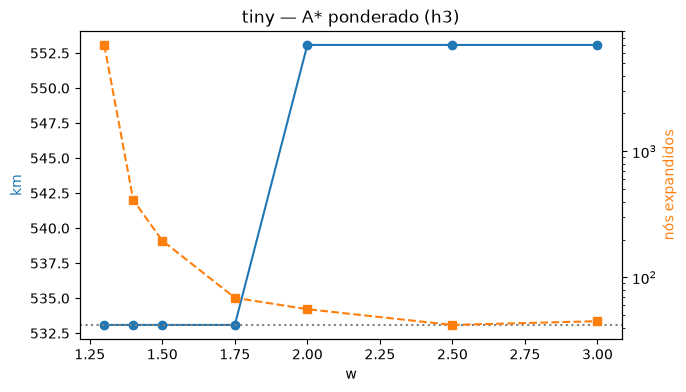

In [7]:
rows = []
for w in (1.3, 1.4, 1.5, 1.75, 2.0, 2.5, 3.0):
    r = weighted_astar(tiny, h_mst, w, max_expansions=100_000)
    rows.append(dict(w=w, km=r.cost, expandidos=r.expanded, segundos=round(r.seconds, 3)))
wa = pd.DataFrame(rows); print(wa)
fig, ax1 = plt.subplots(figsize=(7, 4))
ax1.plot(wa.w, wa.km, "o-", color="tab:blue"); ax1.axhline(C_star, color="grey", ls=":"); ax1.set_ylabel("km", color="tab:blue")
ax2 = ax1.twinx(); ax2.plot(wa.w, wa.expandidos, "s--", color="tab:orange"); ax2.set_yscale("log"); ax2.set_ylabel("nós expandidos", color="tab:orange")
ax1.set_xlabel("w"); ax1.set_title("tiny — A* ponderado (h3)");

## 4. A\* por viagens

Na segunda formulação, cada ação é uma **viagem completa**, escolhida de um catálogo calculado antes da
pesquisa. Para cada ordem de visita, o regresso ao centro é `max(D + δ, c)` e a viagem é viável se
`D ≤ Dmax`, onde D é a hora de partida. Entre ordens do mesmo conjunto de pedidos, descarta-se a que é
pior ou igual em (km, δ, c, Dmax, hora de carregar): é pior para qualquer partida e qualquer
continuação, por isso a redução é exata.

In [8]:
rows = []
for ds, p in PROBLEMS.items():
    t = time.perf_counter(); cat = catalog(p); t_cat = time.perf_counter() - t
    for name in ("h3_mst", "h4_relaxed"):
        r = astar_trips(p, H[name], max_expansions=50_000, time_limit=300)
        rows.append(dict(dataset=ds, heuristica=name, ordens=cat.raw_orders, opcoes=len(cat.options),
                         catalogo_s=round(t_cat, 1), **{k: v for k, v in r.summary().items() if k not in ("algorithm", "heuristic")}))
trips_tab = pd.DataFrame(rows)
trips_tab

,dataset,heuristica,ordens,opcoes,catalogo_s,cost_km,expanded,generated,pruned,seconds,found,complete
0,tiny,h3_mst,242,111,0.0,533.09,3681,169792,112075,5.436,True,True
1,tiny,h4_relaxed,242,111,0.0,533.09,7,281,163,0.011,True,True
2,small,h3_mst,272062,4067,18.0,NaN,9686,4392731,3385891,300.272,False,False
3,small,h4_relaxed,272062,4067,18.0,757.84,19,39369,25620,3.634,True,True


In [9]:
# comparação direta das duas formulações
stop = inf[(inf.algorithm == "A*")].assign(formulacao="paragem a paragem")
trip = inf[(inf.algorithm == "A*-viagens")].assign(formulacao="viagem a viagem")
both = pd.concat([stop, trip])
both.pivot_table(index=["dataset", "heuristic_name"], columns="formulacao", values=["expanded", "cost_km", "seconds"], aggfunc="first")

cost_km                          expanded                           seconds                
formulacao             paragem a paragem viagem a viagem paragem a paragem viagem a viagem paragem a paragem viagem a viagem
dataset heuristic_name                                                                                                      
small   h1_max_detour                NaN             NaN          150000.0             NaN            83.762             NaN
        h2_min_arcs                  NaN             NaN          150000.0             NaN           125.251             NaN
        h3_mst                       NaN             NaN          150000.0         22353.0           146.140         600.004
        h4_relaxed                   NaN          757.84          150000.0            19.0            82.897           2.846
tiny    h1_max_detour                NaN             NaN         1000000.0             NaN           202.681             NaN
        h2_min_arcs                  NaN             NaN         1000000.0             NaN           216.239             NaN
        h3_mst                    533.09          533.09          709786.0          3681.0           179.620           5.382
        h4_relaxed                533.09          533.09            7302.0             7.0             1.133           0.011

A formulação por viagens corta duas fontes de redundância. Deixa de haver ordens diferentes para
construir a mesma viagem (o catálogo já escolheu as ordens não dominadas), e todas as decisões dentro de
uma viagem passam a ser tomadas de uma vez. Com a h4, que no estado inicial já vale o ótimo nos dois
datasets, o A\* expande no máximo 19 nós (7 no tiny, 19 no small).

## 5. Rotas dos 2 veículos do tiny

{'km': 533.09, 'feasible': True, 'trips': 6, 'late_min': 0.0, 'over_kg': 0.0, 'dwell_excess_min': 0.0, 'unserved': 0, 'deadlock': 0, 'overnight': 0, 'makespan_min': 2188.3, 'route_min': 922.5}
verificador por linha: True
Veículo 1: W→P6→P4→P2→W | W→D1→D6→D7→D5→W
Veículo 2: W→P5→P3→P1→W | W→D11→D4→D10→D12→W | W→D2→D9→W | W→D8→D3→W


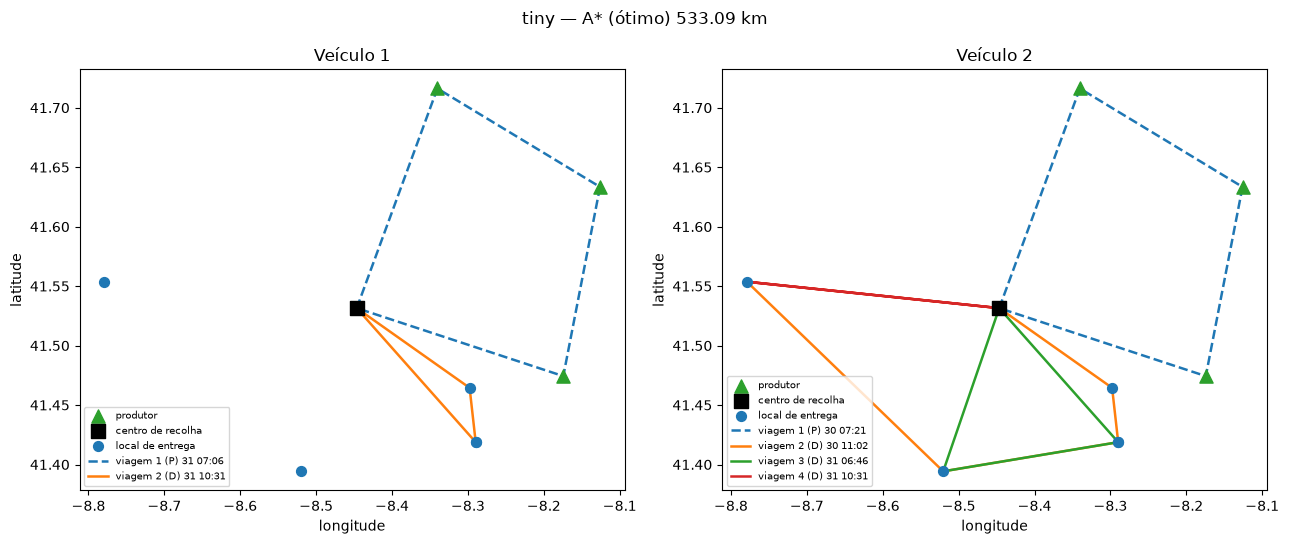

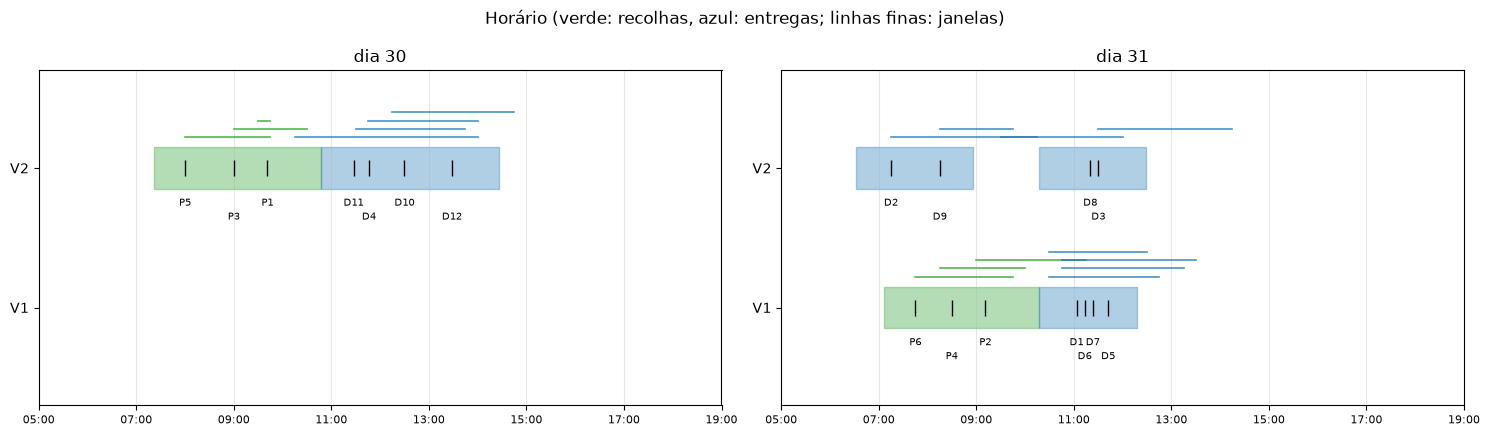

In [10]:
ev = evaluate(tiny, opt)
print(ev.summary()); print("verificador por linha:", check_solution(tiny, ev).valid)
for v, trips in opt.items():
    print(f"Veículo {v}:", " | ".join("W→" + "→".join(t) + "→W" for t in trips))
plot_routes(tiny, opt, f"tiny — A* (ótimo) {ev.km:.2f} km");
plot_gantt(tiny, ev);

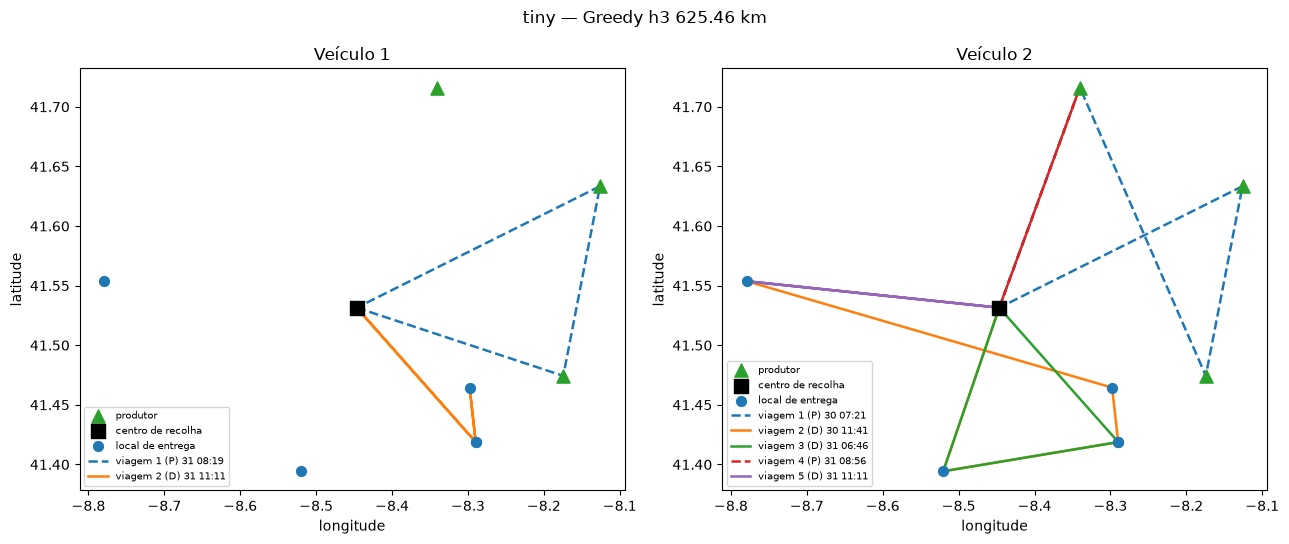

In [11]:
g = greedy(tiny, h_mst)
plot_routes(tiny, g.solution, f"tiny — Greedy h3 {g.cost:.2f} km");

## 6. Rotas ótimas do small

{'km': 757.84, 'feasible': True, 'trips': 6, 'late_min': 0.0, 'over_kg': 0.0, 'dwell_excess_min': 0.0, 'unserved': 0, 'deadlock': 0, 'overnight': 0, 'makespan_min': 2515.7, 'route_min': 1466.7}
verificador por linha: True
Veículo 1: W→P9→W | W→D15→D16→D6→D18→D19→D1→D9→D2→W | W→D23→D5→D25→D14→D11→D17→W
Veículo 2: W→P7→P11→P1→P3→P5→W | W→P8→P12→P2→P4→P6→P10→W | W→D7→D21→D24→D10→D22→D13→D8→D12→D3→D20→D4→W


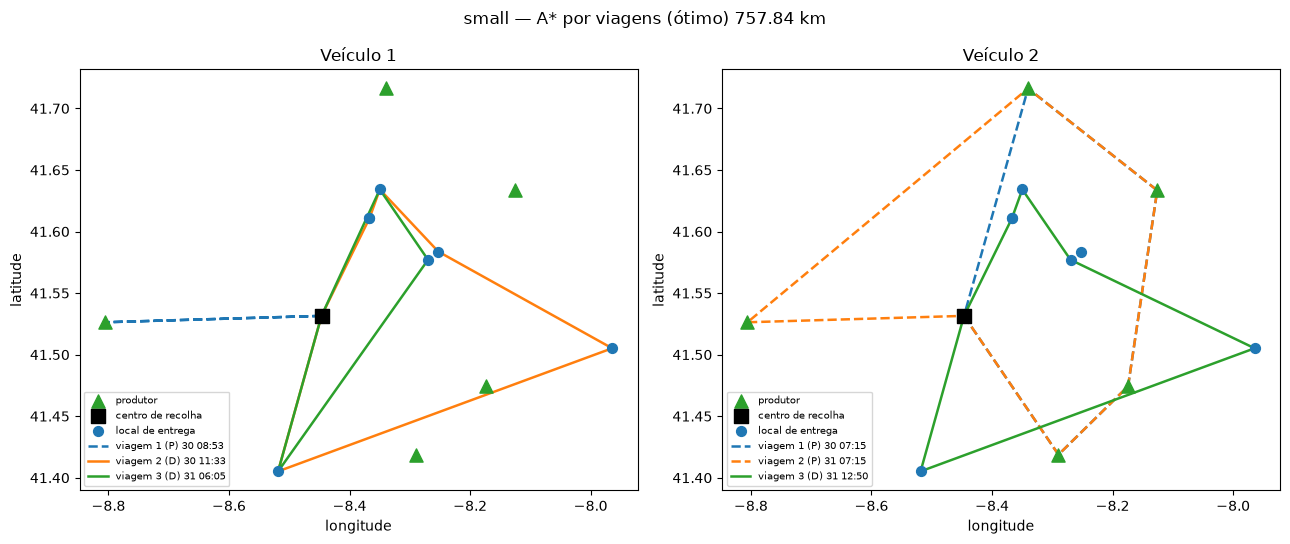

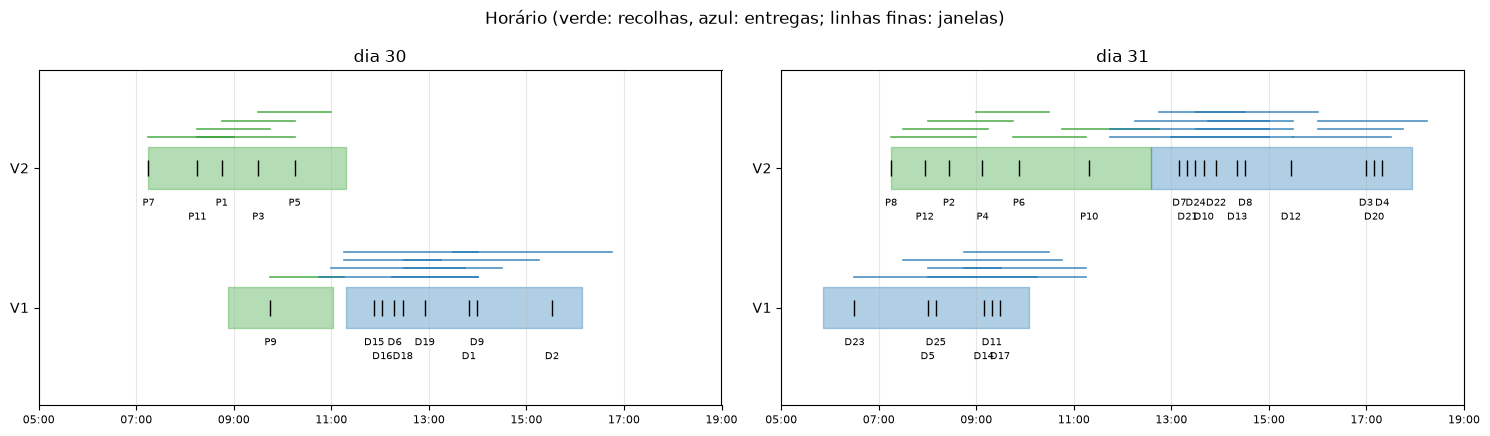

In [12]:
ev_s = evaluate(small, opt_small)
print(ev_s.summary()); print("verificador por linha:", check_solution(small, ev_s).valid)
for v, trips in opt_small.items():
    print(f"Veículo {v}:", " | ".join("W→" + "→".join(t) + "→W" for t in trips))
plot_routes(small, opt_small, f"small — A* por viagens (ótimo) {ev_s.km:.2f} km");
plot_gantt(small, ev_s);

## 7. Conclusões

* **h1 é demasiado fraca.** No estado inicial vale uma pequena fração do ótimo, e o A\* com h1 esgota o
  orçamento sem terminar.
* **h4** (relaxação exata por grupo) vale, no estado inicial, o próprio ótimo nos dois datasets. Com ela
  e com a formulação **por viagens**, o A\* prova o ótimo do tiny e do small com poucas expansões.
* **h3** (MST por grupo, limite tipo 1-árvore, número mínimo de viagens) já resolve o tiny, mas com
  centenas de milhares de expansões.
* **O Greedy encontra soluções em menos de um segundo,** mas sem garantia de qualidade: no tiny fica
  14,6% (h4) a 32,7% (h1) acima do ótimo.
* **O A\* ponderado** dá uma troca controlada entre qualidade e esforço. No tiny, w = 1,4–1,75 encontra o
  ótimo com 69–411 expansões (contra 7 302 do A\* com h4 e 709 786 com h3).
* **No small** (37 pedidos), o A\* paragem a paragem não termina no orçamento com nenhuma heurística, mas
  o A\* por viagens com h4 termina. A escolha das ações conta tanto como a escolha da heurística.